# 📉 Telecom Customer Churn — Exploratory & Diagnostic Analysis



##  Business Problem

Telecom is a subscription-driven business, and customer churn (subscribers leaving for a
competitor or cancelling service) is one of the most expensive problems a telecom company faces.
Acquiring a new customer costs far more than retaining an existing one.

- **How big is the churn problem** and how much **revenue** is at risk?
- **Who is churning** (which customer segments, contracts, tenure stages, services)?
- **Why are customers churning** (competitor offers, poor support, pricing, product gaps)?
- **Can we identify a high-risk segment early enough to retain the customer?**





In [43]:
# IMPORTING REQUIRED LIBRARIES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

from scipy.stats import chi2_contingency, ttest_ind

## Loading Data and Libraries

Download the raw dataset and load it into a pandas DataFrame for analysis.

In [44]:
!gdown 1YxtDfEM2Cz0J3pCSBcDJ9nv0p3OZkLV-

Downloading...
From: https://drive.google.com/uc?id=1YxtDfEM2Cz0J3pCSBcDJ9nv0p3OZkLV-
To: /content/telecom_customer_churn.csv
100% 1.44M/1.44M [00:00<00:00, 54.1MB/s]


In [45]:
# Load the telecom customer churn dataset into a pandas DataFrame
df = pd.read_csv('/content/telecom_customer_churn.csv')


In [46]:
df.head()

,Customer ID,Gender,Age,Married,Number of Dependents,City,Zip Code,Latitude,Longitude,Number of Referrals,...,Payment Method,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,Total Long Distance Charges,Total Revenue,Customer Status,Churn Category,Churn Reason
0,0002-ORFBO,Female,37,Yes,0,Frazier Park,93225,34.827662,-118.999073,2,...,Credit Card,65.6,593.30,0.00,0,381.51,974.81,Stayed,NaN,NaN
1,0003-MKNFE,Male,46,No,0,Glendale,91206,34.162515,-118.203869,0,...,Credit Card,-4.0,542.40,38.33,10,96.21,610.28,Stayed,NaN,NaN
2,0004-TLHLJ,Male,50,No,0,Costa Mesa,92627,33.645672,-117.922613,0,...,Bank Withdrawal,73.9,280.85,0.00,0,134.60,415.45,Churned,Competitor,Competitor had better devices
3,0011-IGKFF,Male,78,Yes,0,Martinez,94553,38.014457,-122.115432,1,...,Bank Withdrawal,98.0,1237.85,0.00,0,361.66,1599.51,Churned,Dissatisfaction,Product dissatisfaction
4,0013-EXCHZ,Female,75,Yes,0,Camarillo,93010,34.227846,-119.079903,3,...,Credit Card,83.9,267.40,0.00,0,22.14,289.54,Churned,Dissatisfaction,Network reliability


In [47]:
df.shape


(7043, 38)

In [48]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 38 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Customer ID                        7043 non-null   object 
 1   Gender                             7043 non-null   object 
 2   Age                                7043 non-null   int64  
 3   Married                            7043 non-null   object 
 4   Number of Dependents               7043 non-null   int64  
 5   City                               7043 non-null   object 
 6   Zip Code                           7043 non-null   int64  
 7   Latitude                           7043 non-null   float64
 8   Longitude                          7043 non-null   float64
 9   Number of Referrals                7043 non-null   int64  
 10  Tenure in Months                   7043 non-null   int64  
 11  Offer                              3166 non-null   objec

## Exploratory Data Analysis (EDA)

Before analyzing churn drivers, we first clean up data types, check for missing values and
duplicate records, and review summary statistics of the numerical fields.

### Data Cleaning & Type Optimization


In [49]:
df.nunique()

,0
Customer ID,7043
Gender,2
Age,62
Married,2
Number of Dependents,10
City,1106
Zip Code,1626
Latitude,1626
Longitude,1625
Number of Referrals,12


In [50]:
# Calculate the percentage of missing values for every column

null_summary = df.isna().sum()/len(df)*100
null_summary = null_summary[null_summary>0].sort_values(ascending=False)
print(null_summary)

Churn Category                       73.463013
Churn Reason                         73.463013
Offer                                55.047565
Online Security                      21.666903
Online Backup                        21.666903
Avg Monthly GB Download              21.666903
Internet Type                        21.666903
Streaming Movies                     21.666903
Streaming TV                         21.666903
Device Protection Plan               21.666903
Premium Tech Support                 21.666903
Unlimited Data                       21.666903
Streaming Music                      21.666903
Avg Monthly Long Distance Charges     9.683374
Multiple Lines                        9.683374
dtype: float64


In [51]:
# Convert selected text/label columns to 'category' dtype for memory efficiency and faster groupby performance

df['Gender'] = df['Gender'].astype('category')
df['Married'] = df['Married'].astype('category')
df['Churn Category'] = df['Churn Category'].astype('category')


In [52]:
df.duplicated().sum()

np.int64(0)

In [53]:
df.describe()

,Age,Number of Dependents,Zip Code,Latitude,Longitude,Number of Referrals,Tenure in Months,Avg Monthly Long Distance Charges,Avg Monthly GB Download,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,Total Long Distance Charges,Total Revenue
count,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,6361.000000,5517.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,46.509726,0.468692,93486.070567,36.197455,-119.756684,1.951867,32.386767,25.420517,26.189958,63.596131,2280.381264,1.962182,6.860713,749.099262,3034.379056
std,16.750352,0.962802,1856.767505,2.468929,2.154425,3.001199,24.542061,14.200374,19.586585,31.204743,2266.220462,7.902614,25.104978,846.660055,2865.204542
min,19.000000,0.000000,90001.000000,32.555828,-124.301372,0.000000,1.000000,1.010000,2.000000,-10.000000,18.800000,0.000000,0.000000,0.000000,21.360000
25%,32.000000,0.000000,92101.000000,33.990646,-121.788090,0.000000,9.000000,13.050000,13.000000,30.400000,400.150000,0.000000,0.000000,70.545000,605.610000
50%,46.000000,0.000000,93518.000000,36.205465,-119.595293,0.000000,29.000000,25.690000,21.000000,70.050000,1394.550000,0.000000,0.000000,401.440000,2108.640000
75%,60.000000,0.000000,95329.000000,38.161321,-117.969795,3.000000,55.000000,37.680000,30.000000,89.750000,3786.600000,0.000000,0.000000,1191.100000,4801.145000
max,80.000000,9.000000,96150.000000,41.962127,-114.192901,11.000000,72.000000,49.990000,85.000000,118.750000,8684.800000,49.790000,150.000000,3564.720000,11979.340000


In [54]:
df['Offer'] = df['Offer'].fillna('No Offer')

### Churn Analysis by various fields & factors.

#### Overall Churn KPIs

In [55]:

# Binary: 1 = Churned, Null value will become 0 as those are stayed customers
df['churned_flag'] = (df['Customer Status']=='Churned').astype(int)

# Considering churned and stayed customer only for further analysis
base = df[df['Customer Status']!='Joined']


churn_rate = round(base['churned_flag'].mean()*100,2)

# 'Joined' customers are brand-new and have no churn outcome yet, so they are
# excluded from churn-rate calculations to avoid biasing the results.

print(f'Total Customers: {len(df)}')
print(f'"Resolved base (analysis): {len(base)}')
print(f'  -Stayed: {(base['churned_flag']==0).sum()}')
print(f'  -Churned: {(base['churned_flag']==1).sum()}')
print(f'  -Joined (No outcome yet): {(df['Customer Status']=='Joined').sum()}')
print()
print(f'Overall Churn Rate: {churn_rate}%')


Total Customers: 7043
"Resolved base (analysis): 6589
  -Stayed: 4720
  -Churned: 1869
  -Joined (No outcome yet): 454

Overall Churn Rate: 28.37%


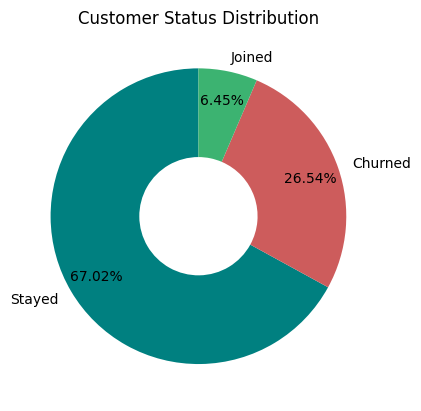

Customer Status
Stayed     4720
Churned    1869
Joined      454
Name: count, dtype: int64


In [56]:
df['Customer Status'].value_counts().plot.pie(autopct='%.2f%%',colors=['teal','indianred','mediumseagreen'],startangle=90,wedgeprops= {'width':0.6},pctdistance=0.80,ylabel='')
plt.title('Customer Status Distribution')
plt.show()
print(df['Customer Status'].value_counts())

#### Churn Category and primary reason

Compare churn volume by broad churn category and the top 10 specific churn reasons.

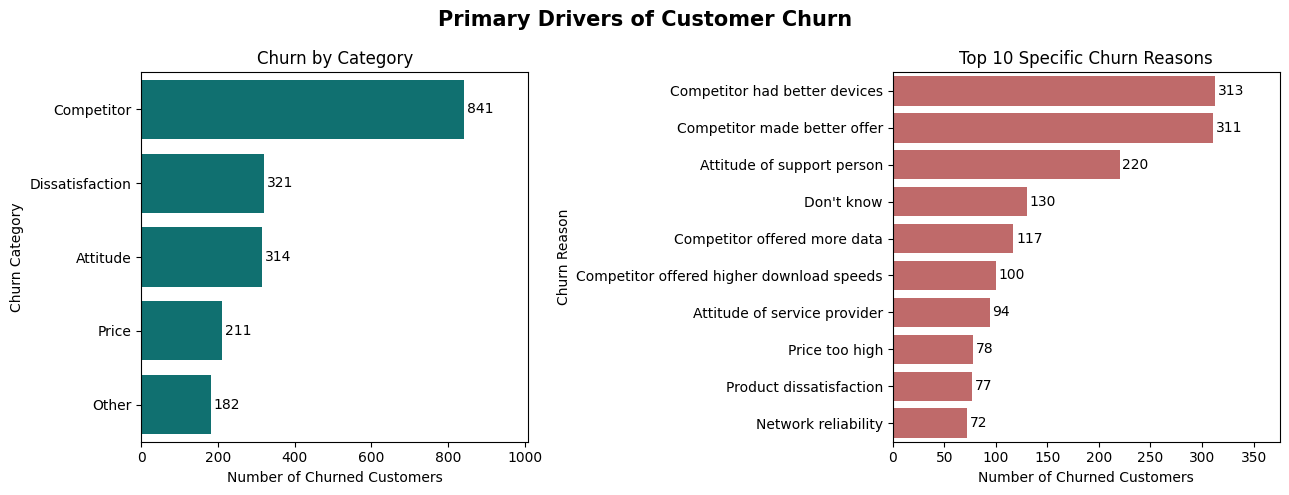

In [57]:

churn_cat = base.loc[base['churned_flag']==1,'Churn Category'].value_counts().sort_values(ascending=False).reset_index()
churn_reason = base.loc[base['churned_flag']==1,'Churn Reason'].value_counts().head(10).reset_index()  # Top 10 specific reasons


plt.figure(figsize=(13,5))
plt.subplot(1,2,1)
ax = sns.barplot(data = churn_cat, y = 'Churn Category', x ='count',color='teal', order = churn_cat['Churn Category'])
for i in ax.containers:
  ax.bar_label(i,padding=2)
plt.xlabel('Number of Churned Customers')
plt.title('Churn by Category')
plt.xlim(0,churn_cat['count'].max()*1.2)

plt.subplot(1,2,2)
ax = sns.barplot(data = churn_reason, y = 'Churn Reason', x ='count',color='indianred' )
for i in ax.containers:
  ax.bar_label(i,padding=2)
plt.xlim(0,churn_reason['count'].max() *1.2)
plt.xlabel('Number of Churned Customers')
plt.title('Top 10 Specific Churn Reasons')
plt.suptitle('Primary Drivers of Customer Churn', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()


> **Insight:** Customers are leaving for two main reasons: competitors are offering better plans, and our customer support is frustrating them.

#### Demographics

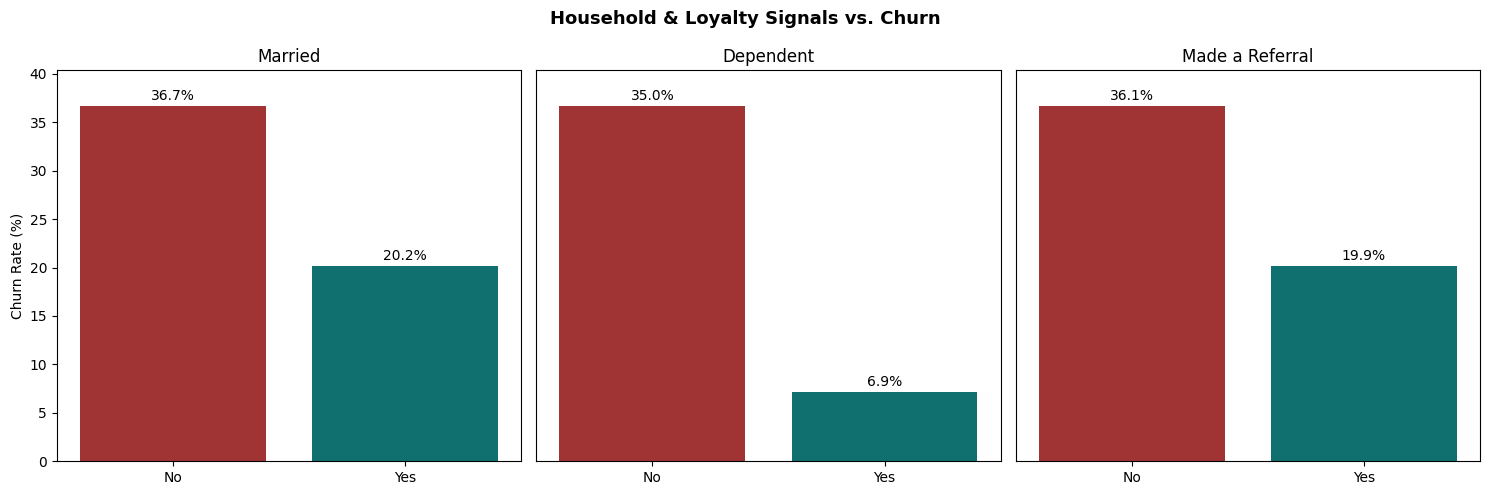

In [58]:
# churn rate by Marital Status / Dependents / Referral activity

base['Has_Dependent'] = np.where(base['Number of Dependents'] >0,'Yes','No')
base['Has_Referrals'] = np.where(base['Number of Referrals'] >0,'Yes','No')

Married = (base.groupby('Married')['churned_flag'].mean()*100).reset_index()
Dependent= (base.groupby('Has_Dependent')['churned_flag'].mean()*100).reset_index()
Referral= (base.groupby('Has_Referrals')['churned_flag'].mean()*100).reset_index()

#-----------------------------------------------------------------------------------------------------

fig, axes = plt.subplots(1,3,figsize=(15,5))
sns.barplot(data = Married,x='Married',y='churned_flag',palette=['firebrick','teal'],ax = axes[0])


axes[0].set_ylim(0,Married['churned_flag'].max()*1.1)
axes[0].set_ylabel('Churn Rate (%)')
axes[0].set_xlabel('')
axes[0].set_title('Married')


sns.barplot(data = Dependent,x='Has_Dependent',y='churned_flag',palette=['firebrick','teal'],ax = axes[1])

axes[1].set_ylim(0,Dependent['churned_flag'].max()*1.1)
axes[1].set_ylabel('')
axes[1].set_xlabel('')
axes[1].set_yticks([])
axes[1].set_title('Dependent')


sns.barplot(data = Referral,x='Has_Referrals',y='churned_flag',palette=['firebrick','teal'],ax = axes[2])


axes[2].set_ylim(0,Referral['churned_flag'].max()*1.1)
axes[2].set_ylabel('')
axes[2].set_xlabel('')
axes[2].set_yticks([])
axes[2].set_title('Made a Referral')
plt.suptitle('Household & Loyalty Signals vs. Churn', fontsize=13, fontweight='bold')
for ax in axes:
  for i in ax.containers:
    ax.bar_label(i,padding=2,fmt='%.1f%%')

plt.tight_layout()
plt.show()

- Customers without family or social ties (unmarried, no dependents, no referrals) are highly likely to leave, with churn rates consistently around 35–37%.
- Family and social ties make customers want to stay. If a customer is dependents, their chance of canceling is only 6.9%. Being married or referring someone also cuts their risk of leaving by half.

Age and Gender

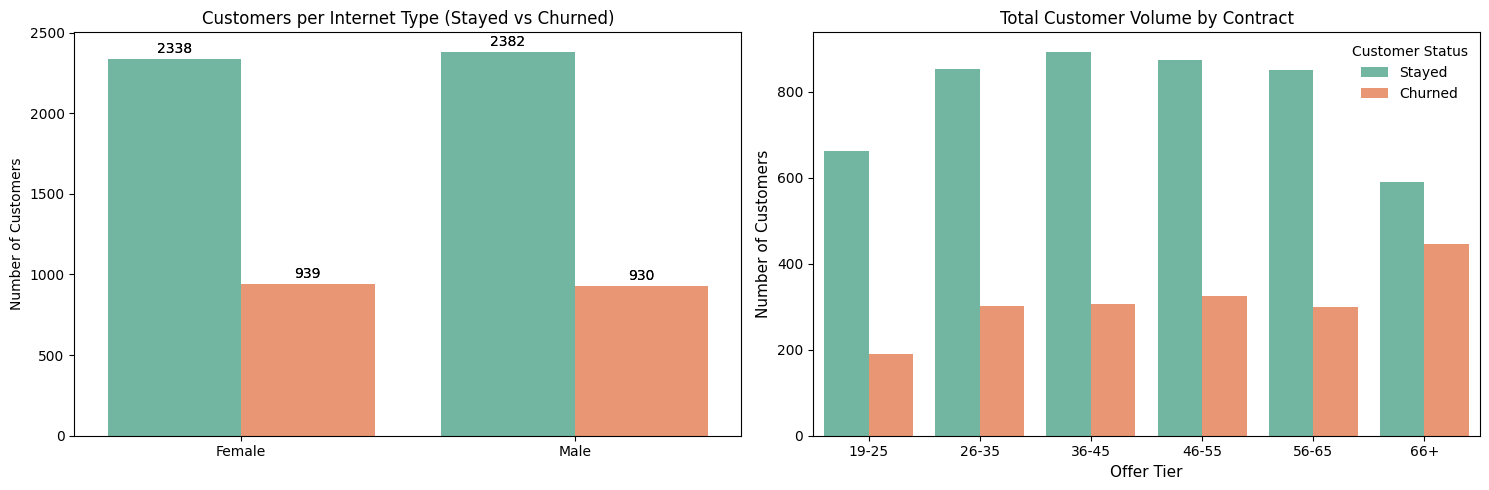

In [59]:
bins = [18, 25, 35, 45, 55, 65, np.inf]
labels = ['19-25', '26-35', '36-45', '46-55', '56-65', '66+']
base['Age Group'] = pd.cut(base['Age'], bins=bins, labels=labels)

Age_x_status = pd.crosstab(index=base['Age Group'], columns = base['Customer Status'])

fig, axes = plt.subplots(1,2, figsize=(15,5))

sns.countplot(data=base, x='Gender', hue='Customer Status', ax=axes[0], palette='Set2')
for i in axes[0].containers:
    axes[0].bar_label(i, padding=2)
axes[0].set_title('Customers per Internet Type (Stayed vs Churned)')
axes[0].set_xlabel('')
axes[0].set_ylabel('Number of Customers')
axes[0].get_legend().remove()

sns.countplot(data=base, x='Age Group', hue='Customer Status', ax=axes[1], palette='Set2')
for i in axes[0].containers:
    axes[0].bar_label(i, padding=2)
axes[1].set_title('Total Customer Volume by Contract', fontsize=12)
axes[1].set_xlabel('Offer Tier', fontsize=11)
axes[1].set_ylabel('Number of Customers', fontsize=11)
axes[1].tick_params(axis='x', rotation=0)


axes[1].legend(title='Customer Status', frameon=False, loc='upper right')

plt.tight_layout()
plt.show()

- Gender and Age have no significant impact on customer churn

#### Contract Types

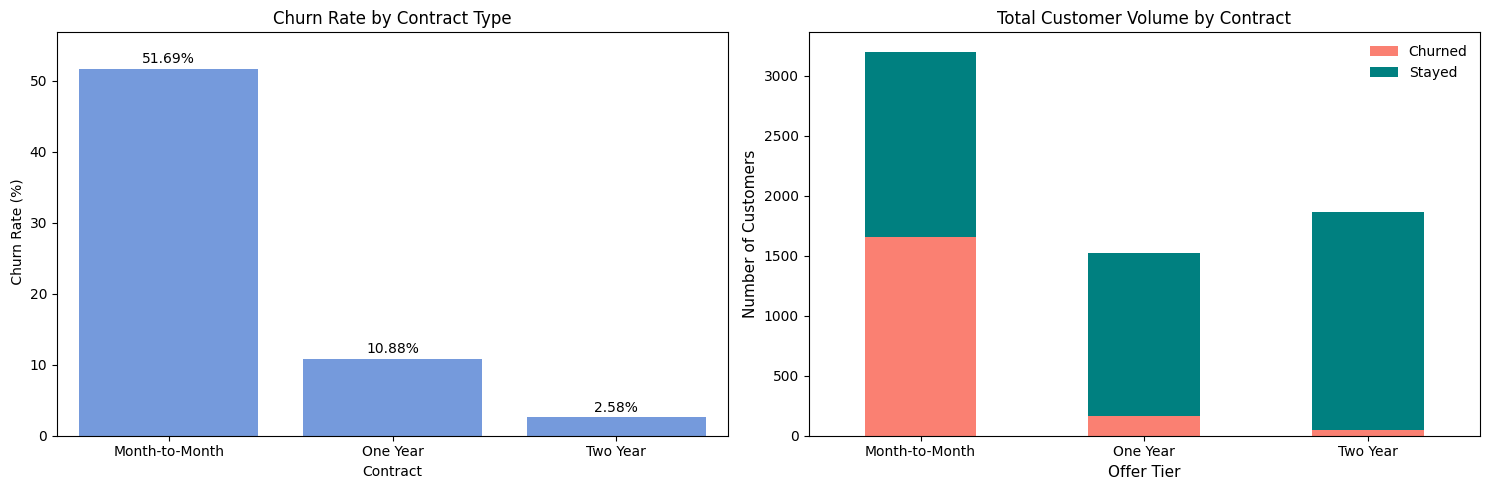

         Contract  total_customer  churn_customer  churn_rate
0  Month-to-Month            3202            1655       51.69
1        One Year            1526             166       10.88
2        Two Year            1861              48        2.58


In [60]:
contract = base.groupby('Contract').agg(total_customer =('churned_flag','count'),churn_customer = ('churned_flag','sum'),churn_rate =('churned_flag','mean')).reset_index()
contract['churn_rate'] = round(contract['churn_rate']*100,2)

contract_x_status = pd.crosstab(index=base['Contract'], columns = base['Customer Status'])

fig, axes = plt.subplots(1,2, figsize=(15,5))

a = sns.barplot(data = contract, x = 'Contract', y='churn_rate',color = 'cornflowerblue',ax=axes[0])
for i in a.containers:
  a.bar_label(i,padding=2,fmt='%.2f%%')
axes[0].set_title('Churn Rate by Contract Type')
axes[0].set_ylim(0,contract['churn_rate'].max()*1.1)
axes[0].set_ylabel(' Churn Rate (%)')

contract_x_status.plot(kind='bar',stacked=True,color=['salmon','teal'],ax=axes[1])
axes[1].set_title('Total Customer Volume by Contract', fontsize=12)
axes[1].set_xlabel('Offer Tier', fontsize=11)
axes[1].set_ylabel('Number of Customers', fontsize=11)
axes[1].tick_params(axis='x', rotation=0)


axes[1].legend(title='', frameon=False, loc='upper right')

plt.tight_layout()
plt.show()
print(contract)

- Customers on month-to-month plans are the most likely to cancel, with over half (51.69%) leaving.
- More the customer stay, less likely to churn

#### Offers

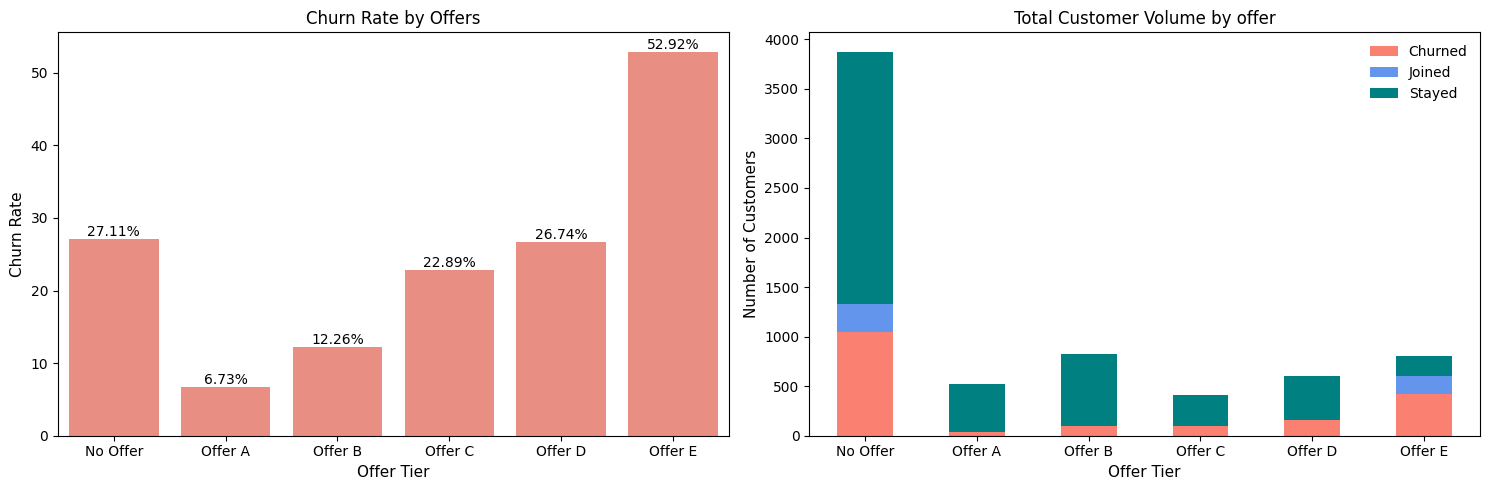

In [61]:
offer = df.groupby('Offer').agg(total_customer =('churned_flag','count'),churn_customer = ('churned_flag','sum'),churn_rate =('churned_flag','mean')).reset_index()
offer['churn_rate'] = round(offer['churn_rate']*100,2)

Offer_x_status = pd.crosstab(index=df['Offer'], columns = df['Customer Status'])

fig, axes = plt.subplots(1,2, figsize=(15,5))
b = sns.barplot(data = offer, x = 'Offer', y='churn_rate',color = 'salmon',ax=axes[0])
for i in b.containers:
  b.bar_label(i,fmt='%.2f%%')
axes[0].set_title('Churn Rate by Offers', fontsize=12)
axes[0].set_xlabel('Offer Tier', fontsize=11)
axes[0].set_ylabel('Churn Rate', fontsize=11)

Offer_x_status.plot(kind='bar',stacked=True,color=['salmon','cornflowerblue','teal'],ax=axes[1])
axes[1].set_title('Total Customer Volume by offer', fontsize=12)
axes[1].set_xlabel('Offer Tier', fontsize=11)
axes[1].set_ylabel('Number of Customers', fontsize=11)
axes[1].tick_params(axis='x', rotation=0)


axes[1].legend(title='', frameon=False, loc='upper right')

plt.tight_layout()
plt.show()


In [62]:
offer_summary = df.groupby('Offer').agg(Min_Tenure=('Tenure in Months', 'min'),
    Max_Tenure=('Tenure in Months', 'max'),
    Customer_Count=('Tenure in Months', 'count'),
    churned_customer= ('churned_flag','sum'),
    churned_pct =('churned_flag','mean'))
offer_summary['Tenure_Period'] = offer_summary['Max_Tenure'] - offer_summary['Min_Tenure']
offer_summary['churned_pct'] = offer_summary['churned_pct'].mul(100).round(2)
offer_summary = offer_summary[['Min_Tenure','Max_Tenure','Tenure_Period','Customer_Count','churned_customer','churned_pct']]
offer_summary

,Min_Tenure,Max_Tenure,Tenure_Period,Customer_Count,churned_customer,churned_pct
Offer,,,,,,
No Offer,1,72,71,3877,1051,27.11
Offer A,66,72,6,520,35,6.73
Offer B,40,65,25,824,101,12.26
Offer C,24,39,15,415,95,22.89
Offer D,10,23,13,602,161,26.74
Offer E,1,10,9,805,426,52.92


- Offers are tied to tenure: This chart shows that each offer targets a completely different stage of the customer lifecycle (e.g., Offer E for months 1-10 vs. Offer A for months 66-72), meaning their success rates cannot be compared head-to-head.   
- Highest Churn Rate: Offer E shows a massive 52.9% churn rate, which simply reflects the high drop-off risk of brand-new customers.   
- Highest Churn Volume: Customers with "No Offer" represent our biggest absolute loss, accounting for 1,051 total cancellations across the 72-month lifespan.

#### Phone - Internet and add-on technical services

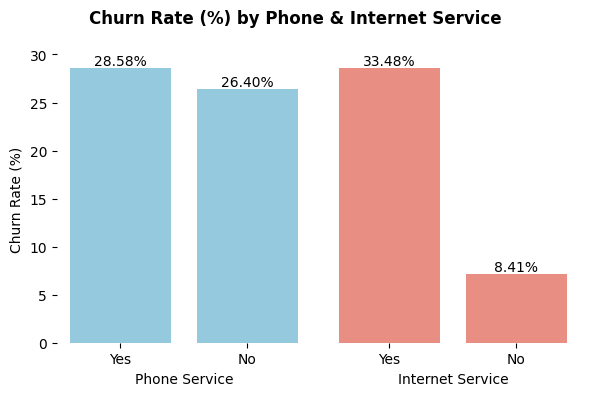

In [63]:
fig, axes = plt.subplots(1,2,figsize=(6,4))

a = sns.barplot( x = base['Phone Service'], y = base['churned_flag']*100, ax = axes[0],ci=None, color='skyblue')
for i in a.containers:
  a.bar_label(i,fmt= '%.2f%%')
axes[0].set_frame_on(False)
axes[0].set_ylabel('Churn Rate (%)')

b = sns.barplot( x = base['Internet Service'], y = base['churned_flag']*100, ax = axes[1],ci=None, color='salmon')
for i in b.containers:
  b.bar_label(i,fmt= '%.2f%%')
axes[1].set_frame_on(False)
axes[1].set_ylabel('Churn Rate (%)')
axes[1].set_ylabel('')
axes[1].set_yticks([])
plt.suptitle('Churn Rate (%) by Phone & Internet Service',weight='bold')
plt.tight_layout()
plt.show()


- Subscribing to our internet service is a major risk factor for leaving the company entirely, with 33.48% of these users churning compared to just 8.41% of those without it.


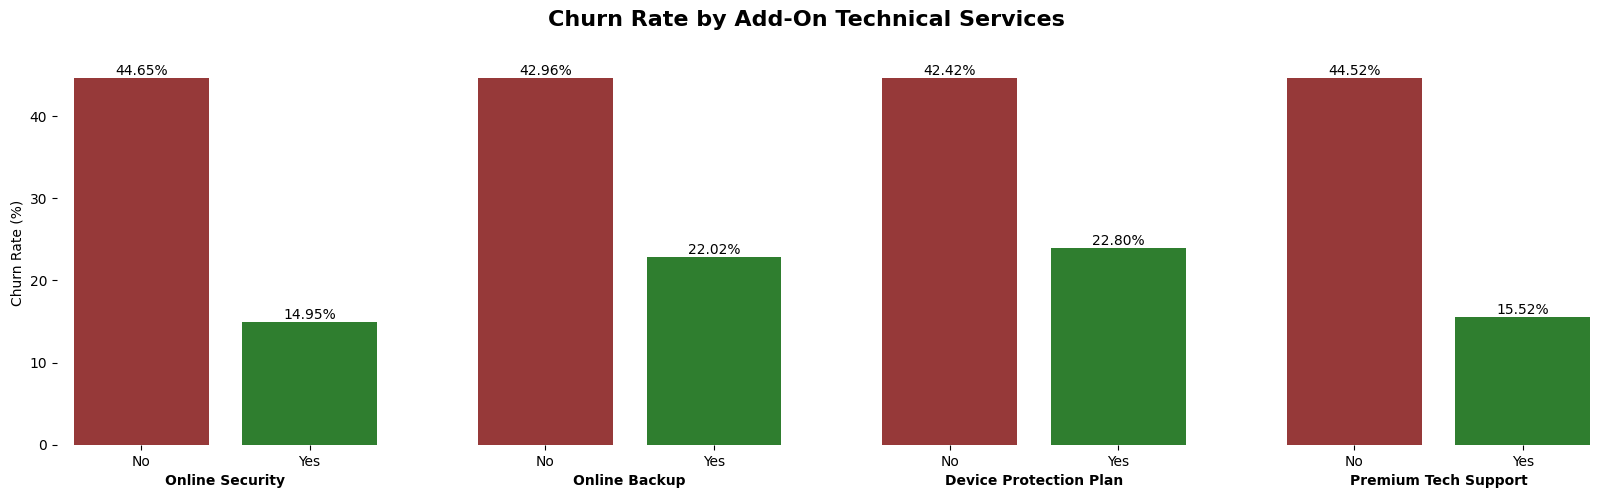

In [64]:
# Churn rate (%) for each internet add-on/protection service subscribed


OS = round(base.groupby('Online Security')['churned_flag'].mean()*100,2).reset_index() # Online Security

OB = round(base.groupby('Online Backup')['churned_flag'].mean()*100,2).reset_index() # Online Backup

DP = round(base.groupby('Device Protection Plan')['churned_flag'].mean()*100,2).reset_index() # Device Protection Plan

PS = round(base.groupby('Premium Tech Support')['churned_flag'].mean()*100,2).reset_index() # Premium Tech Support

# 4-panel comparison chart, one panel per add-on service
plt.figure(figsize=(20,5))
ax = plt.subplot(1,4,1)
a = sns.barplot(data = OS, x = 'Online Security',y='churned_flag',palette=['brown','forestgreen'])
for i in a.containers:
  a.bar_label(i,fmt='%.2f%%')
plt.ylabel('Churn Rate (%)')
plt.xlabel('Online Security',weight='bold')
plt.box(False)


plt.subplot(1,4,2,sharex=ax)
b = sns.barplot(data = OB, x = 'Online Backup',y='churned_flag',palette=['brown','forestgreen'])
for i in b.containers:
  b.bar_label(i,fmt='%.2f%%')
plt.ylabel('')
plt.box(False)
plt.yticks([])
plt.xlabel('Online Backup',weight='bold')

plt.subplot(1,4,3,sharex=ax)
c = sns.barplot(data = DP, x = 'Device Protection Plan',y='churned_flag',palette=['brown','forestgreen'])
for i in c.containers:
  c.bar_label(i,fmt='%.2f%%')
plt.ylabel('')
plt.box(False)
plt.yticks([])
plt.xlabel('Device Protection Plan',weight='bold')

plt.subplot(1,4,4,sharex=ax)
d = sns.barplot(data = PS, x = 'Premium Tech Support',y='churned_flag',palette=['brown','forestgreen'])
for i in d.containers:
  d.bar_label(i,fmt='%.2f%%')
plt.ylabel('')
plt.box(False)
plt.yticks([])
plt.xlabel('Premium Tech Support',weight='bold')

plt.suptitle('Churn Rate by Add-On Technical Services',fontsize=16, fontweight='bold')
plt.show()


**The Add-On Impact:** Customers who do not use extra technical services leave the company at very high rates, consistently above 42%.

**The Best Protections:** Enrolling customers in Online Security or Premium Tech Support is the most effective way to keep them, as it drops the churn rate all the way down to roughly 15% to 22%.


#### Internet Type

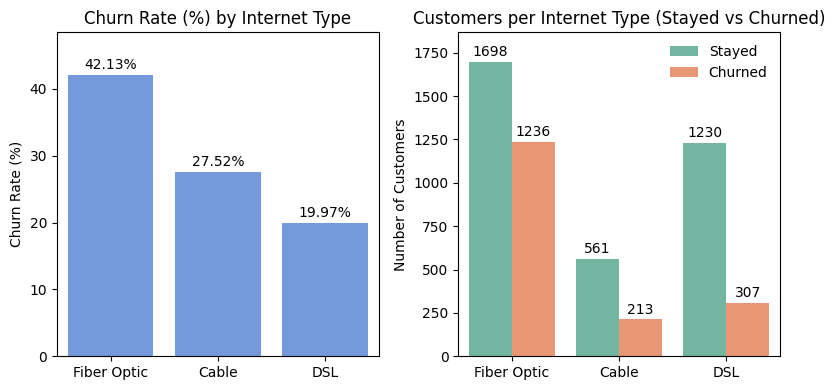

In [65]:
internet_df = base[base['Internet Service']=='Yes']
internet_type_churn = (internet_df.groupby('Internet Type')['churned_flag'].mean()*100).reset_index(name='churn_pct').sort_values('churn_pct', ascending=False)
net_order = internet_type_churn['Internet Type'].tolist()   # highest churn first, used for both panels

fig, axes = plt.subplots(1, 2, figsize=(8, 4))

# left: churn rate
sns.barplot(data=internet_type_churn, x='Internet Type', y='churn_pct',
                order=net_order, color='cornflowerblue', ax=axes[0])
for i in axes[0].containers:
    axes[0].bar_label(i, padding=2, fmt='%.2f%%')
axes[0].set_title('Churn Rate (%) by Internet Type')
axes[0].set_xlabel('')
axes[0].set_ylabel('Churn Rate (%)')
axes[0].set_ylim(0, internet_type_churn['churn_pct'].max()*1.15)

# right: customer counts
sns.countplot(data=base, x='Internet Type', hue='Customer Status',
              order=net_order, ax=axes[1], palette='Set2')
for i in axes[1].containers:
    axes[1].bar_label(i, padding=2)
axes[1].set_title('Customers per Internet Type (Stayed vs Churned)')
axes[1].set_xlabel('')
axes[1].set_ylabel('Number of Customers')
axes[1].legend(frameon=False)
axes[1].set_ylim(0,1698*1.1)
plt.tight_layout()
plt.show()


- Fiber Optic(42.13%) and cabel(27.50%) have significantly higher churn rates.This indicates that these specific connection types are the primary drivers of attrition among your internet users.
- DSL has the least churn rate among all

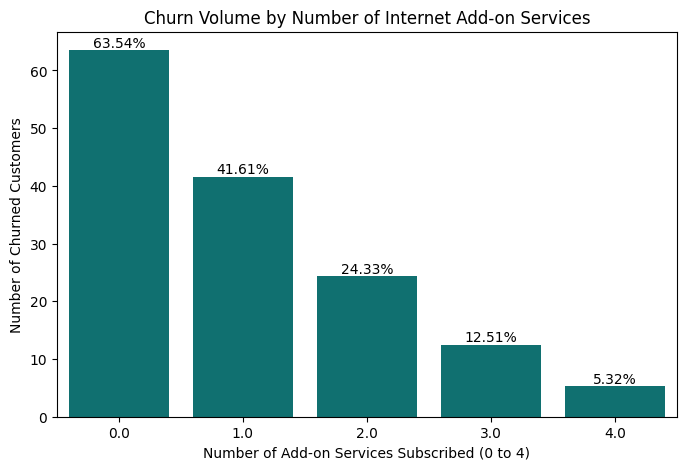

In [66]:
# Total number of protection/support add-ons (0-4) each customer subscribes to
add_ons = ['Online Security', 'Online Backup', 'Device Protection Plan', 'Premium Tech Support']

# When Internet Service is No add-on Service is Null so to remove it. I filtered it out
internet_df = base[base['Internet Service']=='Yes']

internet_df['add_on_count'] = (internet_df[add_ons] == 'Yes').sum(axis=1) # null value will have become zero, Filtered them out already

plt.figure(figsize=(8, 5))
c= sns.barplot(data=internet_df, x='add_on_count', color='teal',y=base['churned_flag']*100,ci=False)
for i in c.containers:
  c.bar_label(i,fmt='%.2f%%')
plt.title('Churn Volume by Number of Internet Add-on Services')
plt.xlabel('Number of Add-on Services Subscribed (0 to 4)')
plt.ylabel('Number of Churned Customers')
plt.show()


- Customers who do not subscribe to any extra internet services make up the vast majority of cancellations, with nearly (63.50%) people are leaving.

- The more add-on services a customer has, the more likely they are to stay, as the total volume of cancellations drops steadily with each new service they add.

In [67]:
internet_df['add_on_count'].value_counts()

,count
add_on_count,
1,1370
2,1340
0,1130
3,935
4,470


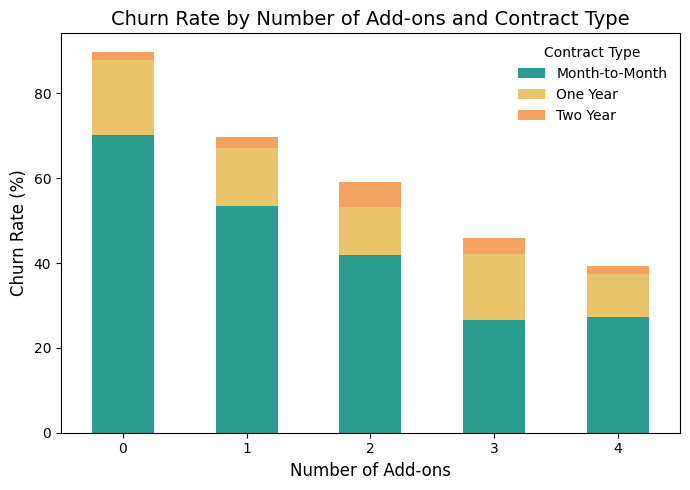

In [68]:
ax = (internet_df.groupby(['Contract', 'add_on_count'])['churned_flag']
         .mean().mul(100).round(2).unstack(0)
     ).plot(kind='bar', stacked=True, color= ['#2A9D8F', '#E9C46A', '#F4A261'] , figsize=(7, 5))


plt.title('Churn Rate by Number of Add-ons and Contract Type', fontsize=14)
plt.xlabel('Number of Add-ons', fontsize=12)
plt.ylabel('Churn Rate (%)', fontsize=12)

plt.xticks(rotation=0)

plt.legend(title='Contract Type', frameon=False, loc='upper right')

plt.tight_layout()

plt.show()

- The data confirms that customers on Month-to-Month contract without any add-on internet service has higher churn rate.

#### Streaming and other additional services


In [69]:
# Churn rate (%) by streaming service subscriptions: TV, Movies, Music

print(base.groupby('Streaming TV')['churned_flag'].mean().mul(100).sort_values(ascending=False).round(2))

print('-'* 35)

print(base.groupby('Streaming Movies')['churned_flag'].mean().mul(100).sort_values(ascending=False).round(2))

print('-'* 35)

print(base.groupby('Streaming Music')['churned_flag'].mean().mul(100).sort_values(ascending=False).round(2))

print('-'* 35)

print(base.groupby('Paperless Billing')['churned_flag'].mean().mul(100).sort_values(ascending=False).round(2))

Streaming TV
No     36.41
Yes    30.62
Name: churned_flag, dtype: float64
-----------------------------------
Streaming Movies
No     36.61
Yes    30.49
Name: churned_flag, dtype: float64
-----------------------------------
Streaming Music
No     36.60
Yes    29.89
Name: churned_flag, dtype: float64
-----------------------------------
Paperless Billing
Yes    35.23
No     17.93
Name: churned_flag, dtype: float64


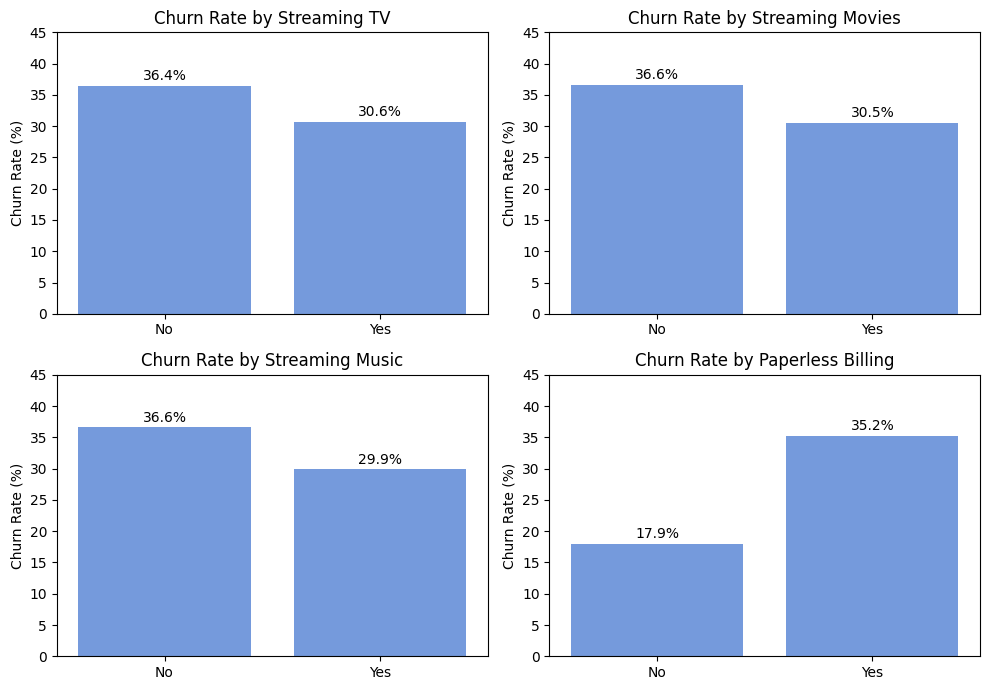

In [70]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
axes = axes.reshape(-1)
# 1: Streaming TV
tv = (base.groupby('Streaming TV')['churned_flag'].mean().mul(100).round(2).reset_index())
sns.barplot(data=tv, x='Streaming TV', y='churned_flag', color='cornflowerblue', ax=axes[0],ci=False)
axes[0].set_title('Churn Rate by Streaming TV')

# 2: Streaming Movies
movies = (base.groupby('Streaming Movies')['churned_flag'].mean().mul(100).round(2).reset_index())
sns.barplot(data=movies, x='Streaming Movies', y='churned_flag', color='cornflowerblue', ax=axes[1],ci=False)
axes[1].set_title('Churn Rate by Streaming Movies')

# 3: Streaming Music
music = (base.groupby('Streaming Music')['churned_flag'].mean().mul(100).round(2).reset_index())
sns.barplot(data=music, x='Streaming Music', y='churned_flag', color='cornflowerblue', ax=axes[2],ci=False)
axes[2].set_title('Churn Rate by Streaming Music')

# 4: Paperless Billing
paperless = (base.groupby('Paperless Billing')['churned_flag'].mean().mul(100).round(2).reset_index())
sns.barplot(data=paperless, x='Paperless Billing', y='churned_flag', color='cornflowerblue', ax=axes[3],ci=False)
axes[3].set_title('Churn Rate by Paperless Billing')

# same y-axis on all four so bars are comparable
for ax in axes:
  for i in ax.containers:
      ax.bar_label(i,fmt='%.1f%%', padding=2)
  ax.set_xlabel('')
  ax.set_ylabel('Churn Rate (%)')
  ax.set_ylim(0, 45)

plt.tight_layout()
plt.show()

- Streaming: Customers without streaming add-ons have a higher cancellation rate (around 36%).

- Billing: Customers using paperless billing are significantly more likely to leave(35.2%)

#### Correlation of Tenure and Financial Metrics

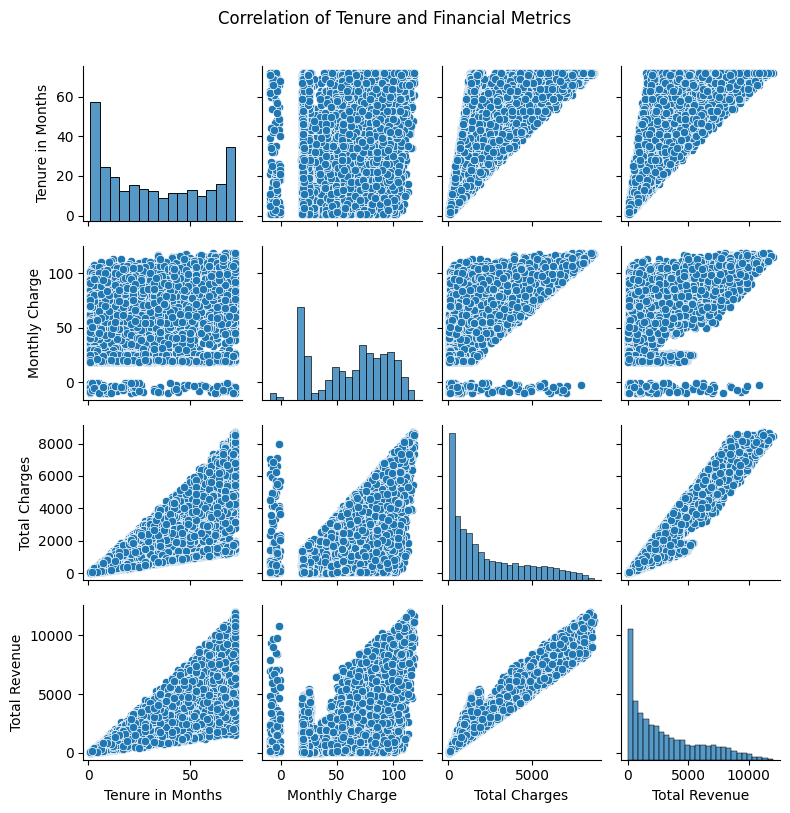

In [71]:

sns.pairplot(data=df,x_vars=['Tenure in Months','Monthly Charge','Total Charges','Total Revenue'],
             y_vars=['Tenure in Months','Monthly Charge','Total Charges','Total Revenue'],height=2,)
plt.suptitle('Correlation of Tenure and Financial Metrics',y=1.01)
plt.tight_layout()
plt.show()

- A negative monthly charge indicates the customer received an account credit on their latest bill, such as a promotional discount or a prorated refund upon canceling. The positive total charge confirms they still have a history of paying for your service.

#### Monthly Bill Size

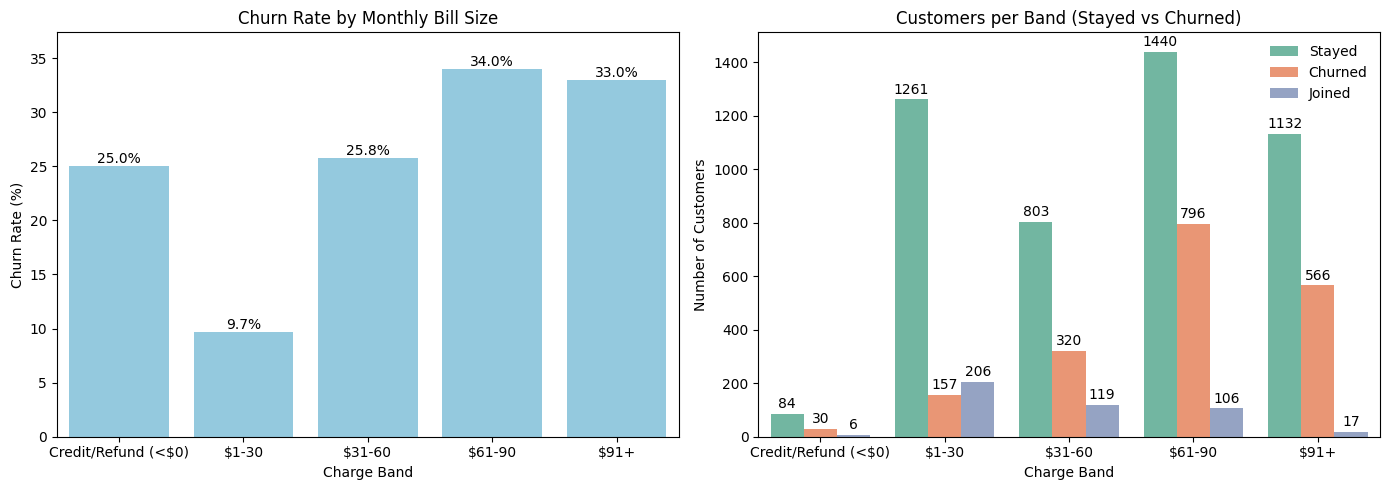

In [72]:
bins = [-np.inf,0,30,60,90,np.inf]
labels = ['Credit/Refund (<$0)','$1-30','$31-60','$61-90','$91+']
df['Charge Band'] = pd.cut(df['Monthly Charge'], bins = bins, labels = labels)


monthly_charged = (df.groupby('Charge Band')['churned_flag'].mean()*100).round(2).sort_values(ascending=False).reset_index(name='pct')
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data = monthly_charged, x = 'Charge Band', y = 'pct',color ='skyblue',ax=axes[0])
for i in axes[0].containers:
  axes[0].bar_label(i,fmt='%.1f%%')
axes[0].set_title('Churn Rate by Monthly Bill Size')
axes[0].set_ylabel('Churn Rate (%)')
axes[0].set_ylim(0,monthly_charged['pct'].max()*1.1)

# right: customer counts
sns.countplot(data=df, x='Charge Band', hue='Customer Status', ax=axes[1],palette='Set2')
for i in axes[1].containers:
    axes[1].bar_label(i, padding=2)
axes[1].set_title('Customers per Band (Stayed vs Churned)')
axes[1].set_ylabel('Number of Customers')
axes[1].legend(frameon=False)

plt.tight_layout()
plt.show()

- Customers with higher monthly bills leave at much higher rates, peaking at a 34% churn rate for those paying more than \$61.
- Furthermore, customers with the lowest bills (\$1 - 30) are the most loyal, with only 11.1% choosing to leave.

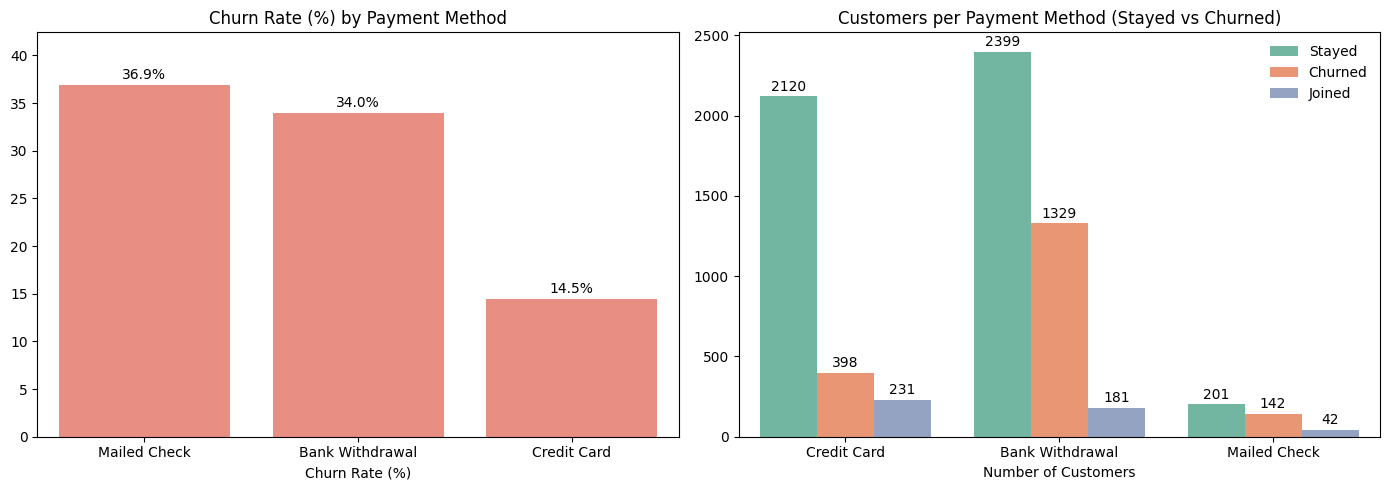

In [73]:
pay_m = (df.groupby('Payment Method')['churned_flag'].mean()*100).round(2).sort_values(ascending=False).reset_index(name='pct')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# left: churn rate
b = sns.barplot(data=pay_m, x='Payment Method', y='pct',color='salmon', ax=axes[0])
for i in b.containers:
    b.bar_label(i, fmt='%.1f%%', padding=2)
axes[0].set_title('Churn Rate (%) by Payment Method')
axes[0].set_ylabel('')
axes[0].set_xlabel('Churn Rate (%)')
axes[0].set_ylim(0, pay_m['pct'].max()*1.15)

# right: customer counts
sns.countplot(data=df, x='Payment Method', hue='Customer Status', ax=axes[1], palette='Set2')
for i in axes[1].containers:
    axes[1].bar_label(i, padding=2)
axes[1].set_title('Customers per Payment Method (Stayed vs Churned)')
axes[1].set_ylabel('')
axes[1].set_xlabel('Number of Customers')
axes[1].legend(frameon=False)

plt.tight_layout()
plt.show()

- Although **mailed checks** have the highest churn rate (37%), the actual number of customers using them is too low to be the primary concern.
- The main focus must be on **Bank Withdrawals**, which drive the vast majority of actual customer losses (1,329 churned at a 34% rate), while Credit Card users remain highly loyal.

#### Tenure Cohort

Show how churn changes across tenure cohorts from the first months of service through six years.

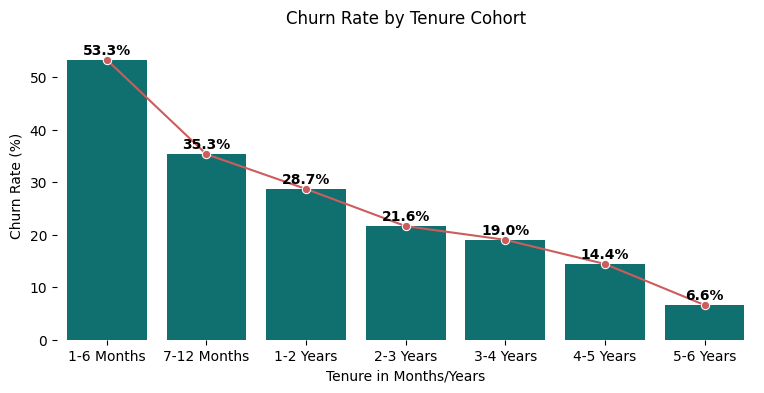

In [74]:
bins = [0, 6, 12, 24, 36, 48, 60, 72]
labels = ['1-6 Months','7-12 Months', '1-2 Years', '2-3 Years', '3-4 Years', '4-5 Years', '5-6 Years']

df['Tenure in Months/Years'] = pd.cut(df['Tenure in Months'],bins = bins,labels = labels)

month_churned = (df.groupby('Tenure in Months/Years')['churned_flag'].mean()*100).reset_index()
plt.figure(figsize=(9,4))
sns.lineplot(data=month_churned,x='Tenure in Months/Years',marker='o',y='churned_flag',color='indianred')
ax = sns.barplot(data = month_churned, x= 'Tenure in Months/Years',y='churned_flag',color='teal')
for i in ax.containers:
  ax.bar_label(i,padding=2,fmt='%.1f%%',weight='bold')
plt.title('Churn Rate by Tenure Cohort')
plt.ylabel('Churn Rate (%)')
plt.ylim(0,month_churned['churned_flag'].max()*1.1)
plt.box(False)
plt.show()

- 53% of customers are overwhelmingly leaving during their very first few months of service.

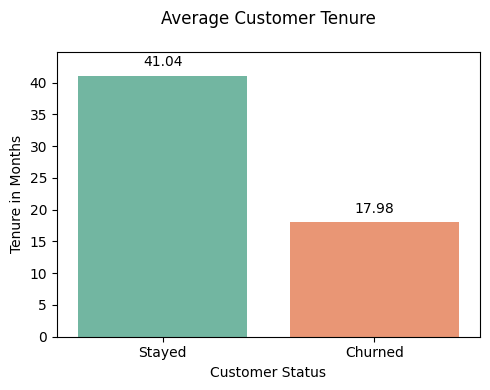

In [75]:
plt.figure(figsize=(5,4))
b = sns.barplot(data = base, x = 'Customer Status', y = 'Tenure in Months',palette='Set2',ci=None)
for i in b.containers:
  b.bar_label(i,fmt = '%.2f',padding=5)

plt.title('Average Customer Tenure',pad =20)
plt.ylim(0, base['Tenure in Months'].mean()*1.3)
plt.tight_layout()
plt.show()

- Churned customers leave much earlier in their lifecycle, averaging a tenure of just 18 months compared to over 41 months for loyal customers.

####  Financial Impact of Churn

In [76]:

total_revenue = df['Total Revenue'].sum()

# Total lifetime revenue lost to churned customers
churned_revenue = df.loc[df['churned_flag']==1, 'Total Revenue'].sum()

# Total lifetime revenue retained from active customers
stayed_revenue = df.loc[df['churned_flag']==0, 'Total Revenue'].sum()
print()
rev_lost_pct = round(churned_revenue/total_revenue,2)*100
print(f'Total Revenue: ${total_revenue:,.0f}')
print(f'Financial Impact: ${churned_revenue:,.0f} lost to churn ({rev_lost_pct}% of total revenue)')
print(f'Stayed Revenue: ${stayed_revenue:,.0f}')



Total Revenue: $21,371,132
Financial Impact: $3,684,460 lost to churn (17.0% of total revenue)
Stayed Revenue: $17,686,672


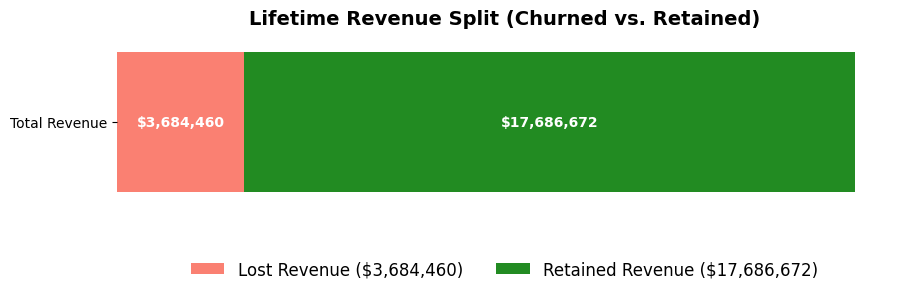

In [77]:
plt.figure(figsize=(10, 2))

b1 = plt.barh('Total Revenue', churned_revenue, color='salmon',
              label=f'Lost Revenue (${churned_revenue:,.0f})')

b2 = plt.barh('Total Revenue', stayed_revenue, left=churned_revenue, color='forestgreen',
              label=f'Retained Revenue (${stayed_revenue:,.0f})')

# Adding the dollar amounts to the center of the bars
plt.bar_label(b1, labels=[f'${churned_revenue:,.0f}'], label_type='center', color='white', weight='bold')
plt.bar_label(b2, labels=[f'${stayed_revenue:,.0f}'], label_type='center', color='white', weight='bold')

plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.3), ncol=2, frameon=False, fontsize=12)
plt.title('Lifetime Revenue Split (Churned vs. Retained)', weight='bold', fontsize=14, pad=15)
plt.xticks([])
plt.box(False)
plt.show()

- Lost $3,684,460 which is (17%) of Total Revenue due to churn

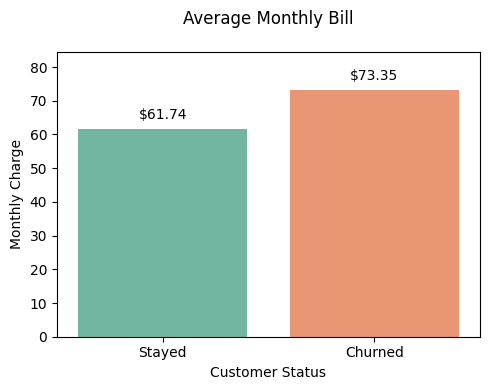

In [78]:
plt.figure(figsize=(5,4))
a = sns.barplot(data = base, x = 'Customer Status', y = 'Monthly Charge',palette='Set2',ci=None)
for i in a.containers:
  a.bar_label(i,fmt='$%.2f',padding=5)

plt.title('Average Monthly Bill',pad =20)
plt.ylim(0, base['Monthly Charge'].mean()*1.3)
plt.tight_layout()
plt.show()


- Customers with higher average monthly bill (\$73.35) tend to leave more compared to those who stay (\$61.74).

#### Geographic

<IPython.core.display.Javascript object>

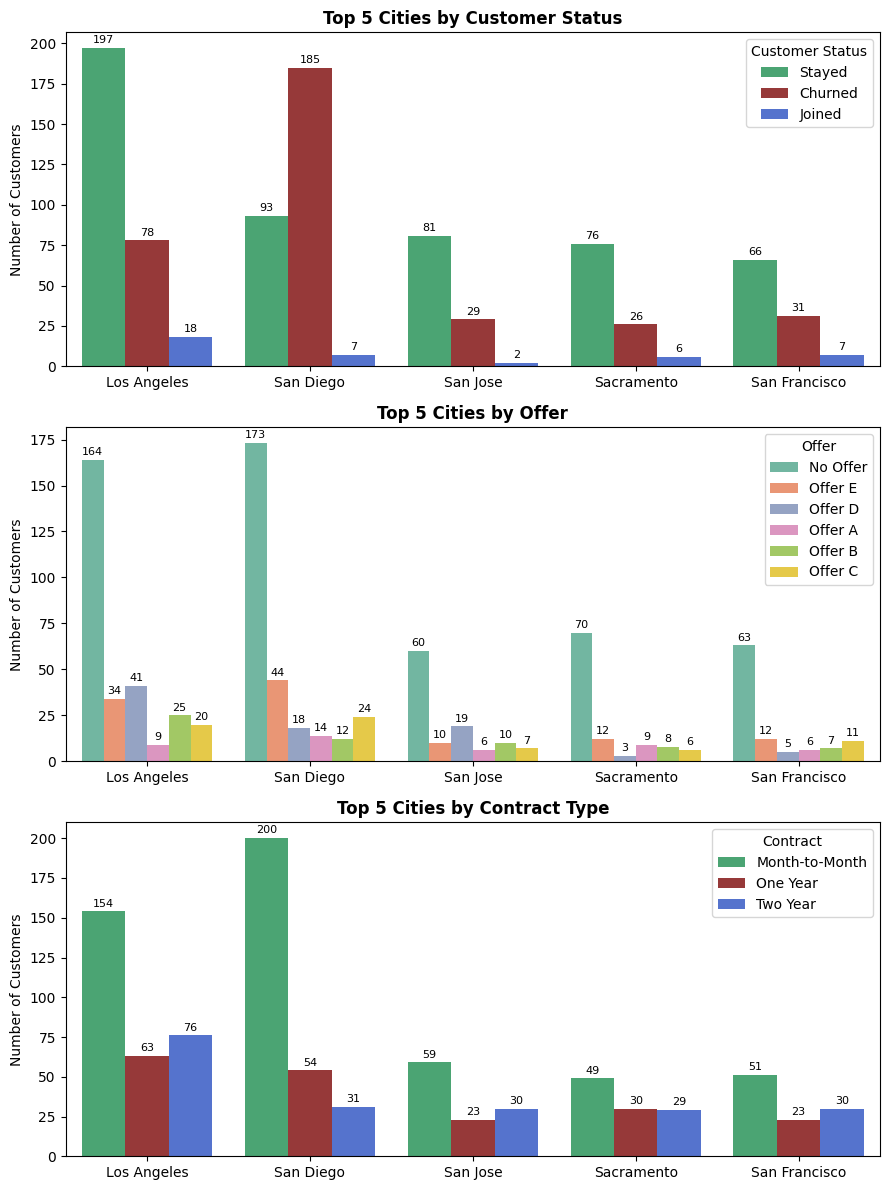

In [79]:
from google.colab import output
output.no_vertical_scroll()

top5 = df['City'].value_counts().index[:5]   # computed once, reused for all 3 charts

fig, axes = plt.subplots(3, 1, figsize=(9, 12))

# 1: contract
sns.countplot(data=df, x='City', hue='Customer Status', order=top5,
              hue_order=['Stayed', 'Churned', 'Joined'],
              palette=['mediumseagreen', 'brown', 'royalblue'], ax=axes[0])
axes[0].set_title('Top 5 Cities by Customer Status',weight='bold')


# 2: offer (nulls shown as "No Offer")
sns.countplot(data=df.assign(Offer=df['Offer'].fillna('No Offer')),
              x='City', hue='Offer', order=top5, palette='Set2', ax=axes[1])
axes[1].set_title('Top 5 Cities by Offer',weight='bold')

# 3: customer status
sns.countplot(data=df, x='City', hue='Contract', order=top5,
              hue_order=['Month-to-Month', 'One Year', 'Two Year'],
              palette=['mediumseagreen', 'brown', 'royalblue'], ax=axes[2])
axes[2].set_title('Top 5 Cities by Contract Type',weight='bold')

for ax in axes:
    for i in ax.containers:
        ax.bar_label(i, padding=2, fontsize=8)
    ax.set_xlabel('')
    ax.set_ylabel('Number of Customers')

plt.tight_layout()
plt.show()

- San Diego is experiencing a severe retention crisis, with roughly twice as many customers canceling their service as staying.
- Even though, Los Angeles has the highest total count of loyal users, it is still losing about 27% of its customer base, meaning a massive volume of people are leaving our biggest market.
- This high churn happens because most customers in the city are on risky month-to-month contracts with either "No Offer" or the poorly performing "Offer E".

### Risk Segmentation

Combining the strongest churn signals found above (**Short tenure**, **Month-to-Month
contracts**, and **No Offer** which leads to high churn) into a single actionable "High-Risk" customer segment
that the business can target for proactive retention.

In [80]:
df['High_risk'] = np.where(((df['Tenure in Months'] <6) &
                            (df['Contract']=='Month-to-Month') &
                            (df['Offer']=='No Offer')),'Yes','No')

risk_summary = df.groupby('High_risk').agg(total_customer= ('churned_flag','count'),
                            total_churn = ('churned_flag','sum'),
                            churn_pct = ('churned_flag','mean')).reset_index()
risk_summary['churn_pct'] = (risk_summary['churn_pct']*100).round(2)
risk_summary

,High_risk,total_customer,total_churn,churn_pct
0,No,6314,1476,23.38
1,Yes,729,393,53.91


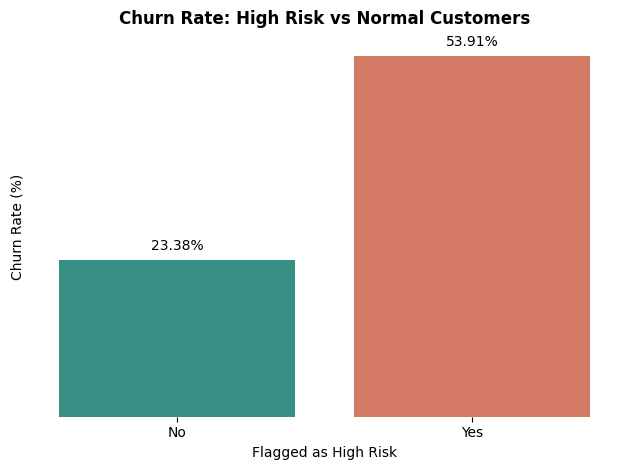

In [81]:
b=sns.barplot(data=risk_summary,x='High_risk', y = 'churn_pct',palette=['#2A9D8F', '#E76F51'])
for i in b.containers:
  b.bar_label(i,fmt = '%.2f%%',padding=5)

plt.title('Churn Rate: High Risk vs Normal Customers',pad=10,fontweight='bold')
plt.xlabel('Flagged as High Risk')
plt.ylabel('Churn Rate (%)')

plt.yticks([])
plt.box(False)
plt.tight_layout()
plt.show()

- 54% of High-Risk customers ended up churning (347 out of 547), proving your warning flag is highly accurate. They churn at nearly three times the rate of normal customers, who only had a 23.4% churn rate.

#### Customer at Risk of churn

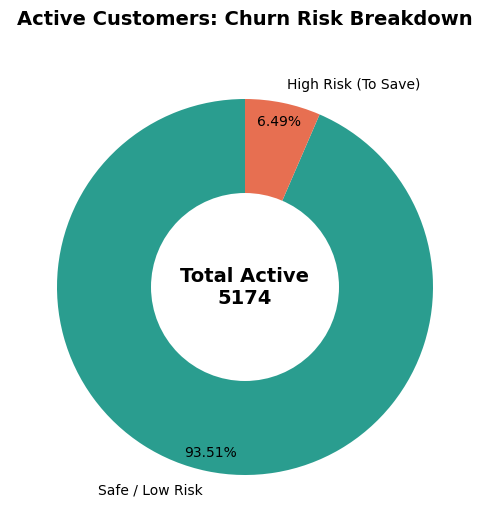

In [82]:
active_cx = df[df['churned_flag'] == 0]

people_to_save = active_cx[active_cx['High_risk'] == 'Yes']

safe_customers = len(active_cx) - len(people_to_save)
risk_customers = len(people_to_save)


sizes = [safe_customers, risk_customers]
labels = ['Safe / Low Risk', 'High Risk (To Save)']


# 3. Create the base pie chart
fig, ax = plt.subplots(figsize=(5, 6))
wedges, texts, autotexts = ax.pie(sizes, labels=labels,
                           colors=['#2A9D8F', '#E76F51'] ,
                            autopct='%1.2f%%',
                            startangle=90,
                            pctdistance=0.90)

# Turning the pie chart into a Donut Chart by drawing a white circle in the middle
center_circle = plt.Circle((0, 0), 0.50, fc='white')
fig.gca().add_artist(center_circle)

#Adding the total customer count in the center of the donut
plt.text(0, 0, f'Total Active\n{len(active_cx)}',
         ha='center', va='center', fontsize=14, fontweight='bold')


plt.title('Active Customers: Churn Risk Breakdown', fontsize=14, fontweight='bold', pad=20)

plt.tight_layout()
plt.show()

- 7.49% falls into the "High Risk" category, providing a focused group for immediate retention campaigns.

Revenue in amount which can be save from the customer at high risk|

In [83]:
Revenue_save = people_to_save['Total Revenue'].sum()
print(f'Revenue can be saved: ${Revenue_save}')

Revenue can be saved: $55820.41


### Correlation Matrix of Numerical Features

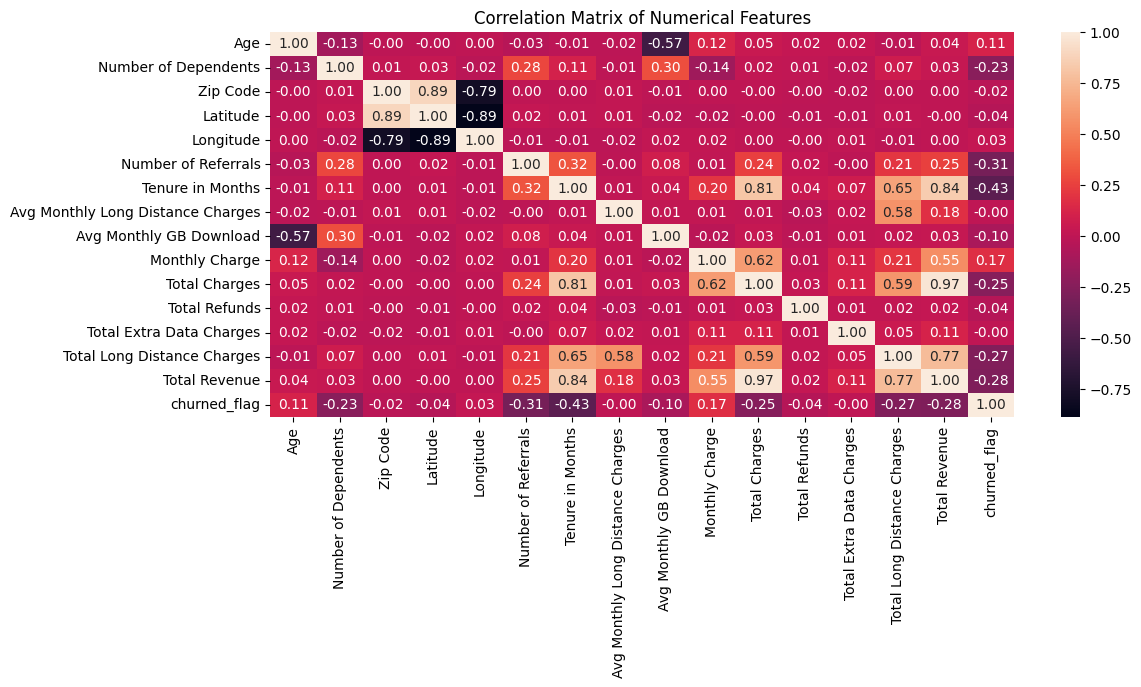

In [84]:
# Correlation heatmap across all numerical features

plt.figure(figsize=(12,5))
sns.heatmap(base.corr(numeric_only=True),annot=True,fmt='.2f')
plt.title('Correlation Matrix of Numerical Features')
plt.show()


- (Tenure in Months) has the strongest negative correlation with churn (-0.43), mathematically proving that the longer a customer stays, the less likely they are to leave.
- Number of Referrals (-0.31) and Number of Dependents (-0.23) both show moderate negative correlations with churn
- (Total Charges) also has a negative correlation with churn (-0.25), higher charges leads to churn


---



In [89]:
churned_df['Offer'].unique()

array(['Offer E', 'Offer D', 'No Offer', 'Offer B', 'Offer A', 'Offer C'],
      dtype=object)

## Top 10 Churn Reason

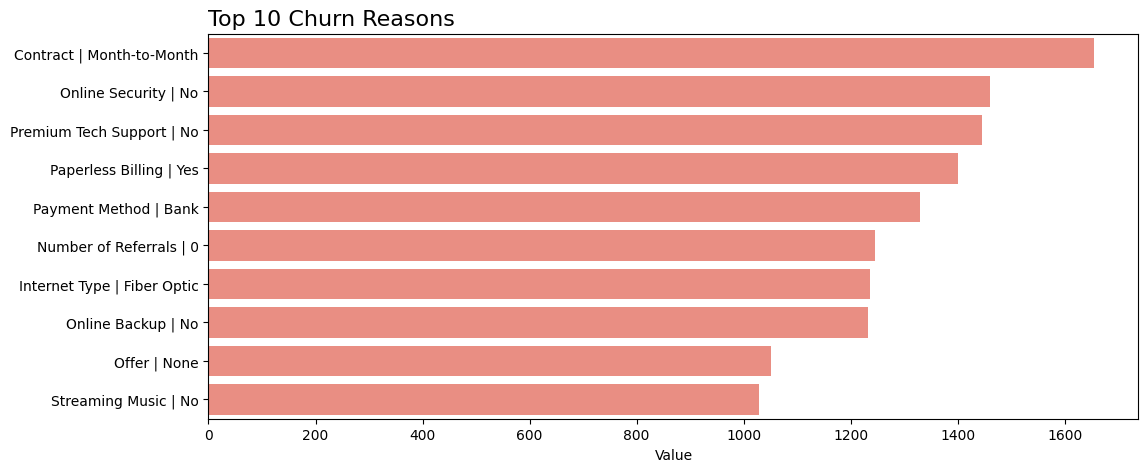

In [94]:

churned_df = df[df['churned_flag'] == 1]

churn_counts = {
    'Contract | Month-to-Month': (churned_df['Contract'] == 'Month-to-Month').sum(),
    'Online Security | No': (churned_df['Online Security'] == 'No').sum(),
    'Premium Tech Support | No': (churned_df['Premium Tech Support'] == 'No').sum(),
    'Paperless Billing | Yes': (churned_df['Paperless Billing'] == 'Yes').sum(),
    'Payment Method | Bank': (churned_df['Payment Method'].str.contains('Bank', na=False)).sum(),
    'Number of Referrals | 0': (churned_df['Number of Referrals'] == 0).sum(),
    'Internet Type | Fiber Optic': (churned_df['Internet Type'] == 'Fiber Optic').sum(),
    'Online Backup | No': (churned_df['Online Backup'] == 'No').sum(),
    'Offer | None': (churned_df['Offer'] == 'No Offer').sum(),
    'Streaming Music | No': (churned_df['Streaming Music'] == 'No').sum()}

# 3. Convert dictionary into a sorted DataFrame
reasons_df = pd.DataFrame(list(churn_counts.items()), columns=['Reason', 'Value'])
reasons_df = reasons_df.sort_values(by='Value', ascending=False)


plt.figure(figsize=(12, 5))
sns.barplot(data=reasons_df, x='Value', y='Reason', color='salmon')
plt.title('Top 10 Churn Reasons', fontsize=16, loc='left')
plt.xlabel('Value')
plt.ylabel('')
plt.show()

## Key Business Insights & Findings
### How big is the churn problem and how much revenue is at risk?
* **Massive Financial Impact:** The business has already lost **$3,684,460**, which accounts for a  17% of total company revenue.
* **Geographic Crisis:** San Diego is losing two customers for every one it keeps. Meanwhile, Los Angeles is losing 27% of its users, resulting highest total number of cancellations

### Who is churning?
* **Contract & Offers:** Month-to-month contracts are highly risky, with over half (51.69%) canceling. Offer E has the worst churn rate (67.62%) becuase it attracts new customer which is already at high risk of early leaving, but customers with "No Offer" cause the highest total number of cancellations (1,051 lost accounts).
* **Product & Services:** Fiber Optic and Cable customers are highly likely to leave, especially if they don't have extra add-on services. Meanwhile, streaming subscriptions don't affect customer loyalty at all.
* **Demographics:** Single customers with no dependents or with no referrals are the most likely to cancel (around 35–37% leave). On the other hand, family and social ties drive loyalty having dependents drops the risk to just 6.9%, and being married or making a referral cuts the risk in half. Furthermore, Age and gender have no impact on cancellations

* **Payment Methods:** Customers paying via **Bank Withdrawal** represent the largest volume of actual business losses (1,329 canceled accounts), whereas Credit Card users remain highly loyal.
- **Charges & Billing :** Customers paying \$61+ represent the biggest loss, peaking at a 35.6% churn rate and the highest total number of cancellations.
Paperless billing is typically the default for flexible, month-to-month contracts, making it easy for customers to leave without penalty.
 - Customer loyalty clearly drops as monthly bills increase; those with the lowest bills (\\$1-$30) are the safest, with only an 11.1% churn rate.

### Why are customers churning?
* **Bad Service & Competition:** Customers usually give two reasons: they found a better deal with a competitor, or they had a bad experience with our customer service.
* **Add-Ons Internet Services**: Customers with only basic internet cancel over 42% of the time. But if they add Online Security or Premium Tech Support, the cancellation rate drops to just 15%.
* **Pricing Issues:** Customers who cancel usually have higher monthly bills (averaging \\$73.35) than those who stay (averaging \$61.74).


### Can we identify a high-risk segment early enough to intervene?
- A small, well-defined High-Risk segment (Month-to-Month + <6 months tenure + No Offer) = Critical Churn Risk
   - Customers who fit this exact profile are highly likely to leave.  Currently, 6.49% of our active customer base falls directly into this High-Risk category. This provides marketing and customer success teams with a small, highly targeted list of users for immediate, proactive retention campaigns before they make the decision to leave which can save \$55,820.amount of Revenue.


---




## Business Recommendations


-  **Target the 3.87% High-Risk segment immediately:** Launch a proactive "first 6 months" retention program for these specific users. Give them personalized setup help or early check-ins so they feel valued before they ever think about canceling.
- When deciding who gets special retention offers, prioritize the customers base on RFM (RFM stands for Recency, Frequency, and Monetary value), rather than treating every churn risk equally.
- **Encourage users to sign longer contracts** Offer our monthly customers a discount or special perk to switch to a 1 or 2 year plan, since being on a monthly plan is the biggest reason people leave.
- **Push Contracts and Offers:** Create new, attractive promotions to encourage month-to-month and "No Offer" customers to sign safer 1-2 years contracts and offers. Offer E attract new customer but most of them leave early.
Change or modify the offer E can be helpful to retain new customer.
- **Include extra features for free in the beginning.** Give new customers add-ons (like Security, Backup, or Tech Support) for free or very cheap during their first few months. people who use these features less likely to quit.
- **Reward Credit Card Payments:** Since bank withdrawals lead to the highest number of cancellations, offer customers a small one-time discount if they switch their payment method to a credit card.
- **Investigate California Cities:** Look closely at San Diego and Los Angeles. Find out if a local competitor is stealing customers with better prices or if there are local customer service issues driving people away.
- **Review fiber-optic pricing and service quality** because it is losing customers faster than our other internet options.
- **Push Referral Programs:** Offer strong financial incentives for single customers to refer friends, artificially building the social ties that cut their cancellation risk in half.
- **Improve Support and Value:** Customers are leaving because of high bills and bad service. Retrain your customer support team to resolve issues quickly, and make sure your core internet plans offer enough value to justify the price compared to competitors.
